# Comparing tTEM with tTEM

In [26]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *

In [27]:
gpu = torch.device('cpu')
cmdl = FewLayerModel.starting_model(3)

In [28]:
from libaarhusxyz import GEX
import plog

In [29]:
gex = GEX("TX11_3x3_1_turn.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


In [30]:
x,y = gex.General['TxLoopPoint'][:, 0], gex.General['TxLoopPoint'][:, 1]
x,y = np.append(x, x[0]),               np.append(y, y[0])
z   = np.ones_like(x)*abs(gex.General['TxCoilPosition'][2])
tx  = Loop(x,y,z)
rx  = Receiver(*abs(gex.General['RxCoilPosition']))

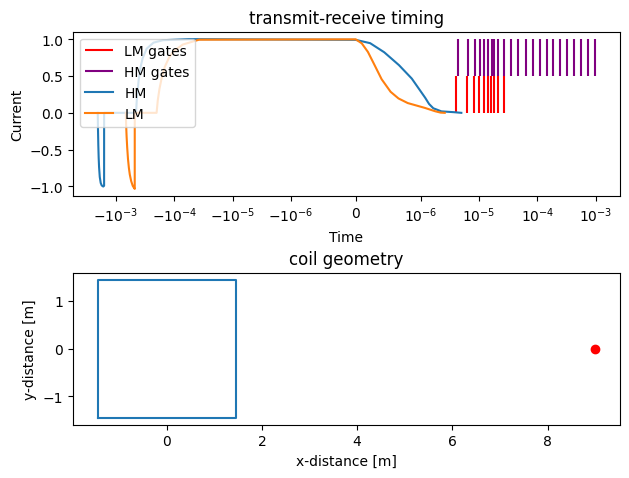

In [31]:
fig,axs=plt.subplots(2,1)
gex.plot(ax=axs[0])
axs[1].plot(tx.x, tx.y)
axs[1].plot(rx.x, rx.y, 'ro')
axs[1].set_aspect('equal')
axs[1].set_xlabel('x-distance [m]')
axs[1].set_ylabel('y-distance [m]')
axs[1].set_title('coil geometry')
axs[0].set_title('transmit-receive timing')
plt.tight_layout()

In [32]:
lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])

LMwv = Waveform(gex.General['WaveformLMPoint'][:, 0], gex.General['WaveformLMPoint'][:, 1])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = DualMoment(tx, rx, [lmgates.to(device), hmgates.to(device)], recfilters, [LMwv, HMwv])

\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:109: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)
\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:408: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=self.device)


In [33]:
res = np.array([10, 200, 20])
thick1 = np.linspace(0.1, 5, 25)

In [34]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)
print(data.shape)

torch.Size([31])


In [35]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)
lgs = [plog.Log(np.log10(res), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

tensor([ 0.1000, 10.0000], dtype=torch.float64)
001	misfit:	6.56
002	misfit:	1.14
increased max step
003	misfit:	0.38

 3
tensor([ 0.3042, 10.0000], dtype=torch.float64)
001	misfit:	5.73
002	misfit:	0.82
increased max step
003	misfit:	0.34

 3
tensor([ 0.5083, 10.0000], dtype=torch.float64)
001	misfit:	5.08
002	misfit:	0.69
increased max step
003	misfit:	0.36

 3
tensor([ 0.7125, 10.0000], dtype=torch.float64)
001	misfit:	4.24
002	misfit:	0.42

 2
tensor([ 0.9167, 10.0000], dtype=torch.float64)
001	misfit:	3.72
002	misfit:	0.47

 2
tensor([ 1.1208, 10.0000], dtype=torch.float64)
001	misfit:	3.25
002	misfit:	0.45

 2
tensor([ 1.3250, 10.0000], dtype=torch.float64)
001	misfit:	3.04
002	misfit:	0.67
increased max step
003	misfit:	0.40

 3
tensor([ 1.5292, 10.0000], dtype=torch.float64)
001	misfit:	1.79
002	misfit:	0.59
increased max step
003	misfit:	0.41

 3
tensor([ 1.7333, 10.0000], dtype=torch.float64)
001	misfit:	1.86
002	misfit:	0.73
increased max step
003	misfit:	0.52
increased max 

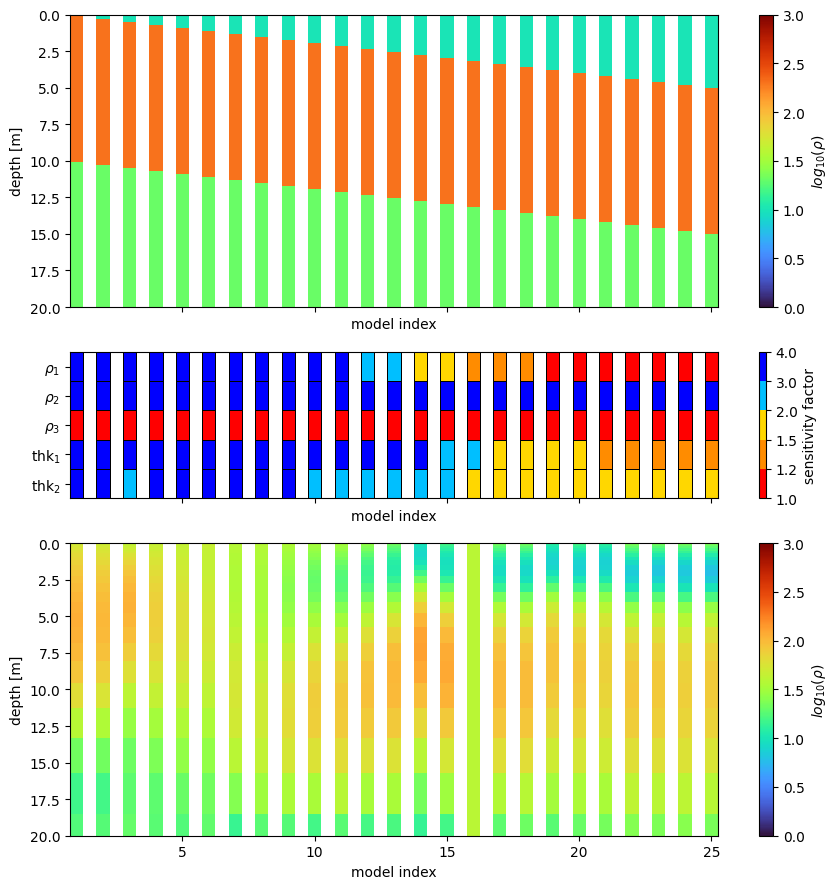

In [36]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(3,1, sharex=True, figsize=(9,9), height_ratios=[2,1,2])
nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)

for i,lg in enumerate(lgs):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([lg.depth_bot[0], 10])
    print(thick)
    dbdt = fwr(sigma, thick)
    
    dbdt_err = compute_relstd(tcat, dbdt, moment=3*9)
    dbdt_err[hm_slice] = compute_relstd(tcat, dbdt, moment=30*9)[hm_slice]


#    inv = Inversion(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = FewLayerModel(sigma, thick, device=gpu)

    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.plot_sensitivity_analysis(ax=axs[1], x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31, device=gpu)
    
    dbdt_with_noise = dbdt + torch.clamp(torch.randn(len(dbdt), device=gpu), -1,1)*dbdt*dbdt_err/2

    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
    rmod = inv2.invert(smoothness=10, iter_cap=20)
    sgm,thk = rmod.values
    clg2 = plog.Log.standard(np.log10(1/sgm.cpu().numpy()), np.cumsum(thk.cpu().numpy()), 'rho')
    ax,pcm=clg2.plot(ax=axs[2], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[2].set_ylim(20,0)
    
for ax in axs:
    ax.set_xlabel('model index')
    ax.set_xticks(range(8, 51, 10))
    ax.set_xticklabels(range(5,26,5))
ax = axs[0]
ax.set_ylabel('depth [m]')
axs[2].set_ylabel('depth [m]')
axs[1].set_ylim(5,0)

plt.colorbar(pcm, ax=axs[0], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
plt.colorbar(pcm, ax=axs[2], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')

plt.tight_layout()

In [ ]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(3,1, sharex=True, figsize=(9,9), height_ratios=[2,1,2])
nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)

for i,lg in enumerate(lgs[:1]):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([lg.depth_bot[0], 10])
    print(thick)
    dbdt = fwr(sigma, thick)
    
    dbdt_err = compute_relstd(tcat, dbdt, moment=3*9)
    dbdt_err[hm_slice] = compute_relstd(tcat, dbdt, moment=30*9)[hm_slice]


#    inv = Inversion(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = FewLayerModel(sigma, thick, device=gpu)

    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.plot_sensitivity_analysis(ax=axs[1], x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31, device=gpu)
    
    dbdt_with_noise = dbdt + torch.clamp(torch.randn(len(dbdt), device=gpu), -1,1)*dbdt*dbdt_err/2

    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
    rmod = inv2.invert(smoothness=10, iter_cap=20)
    sgm,thk = rmod.values
    clg2 = plog.Log.standard(np.log10(1/sgm.cpu().numpy()), np.cumsum(thk.cpu().numpy()), 'rho')
    ax,pcm=clg2.plot(ax=axs[2], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[2].set_ylim(20,0)
    